In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("darkgrid")
plt.rcParams["figure.figsize"] = (12, 6)

DB_PATH = "../data/processed/arc_loot.db"
conn = sqlite3.connect(DB_PATH)

# ARC Loot Economy Analysis

**Pregunta de negocio:** ¿Qué enemigos ARC son las mejores fuentes de loot, y cómo se distribuyen por mapa?

Este análisis ayuda a identificar:
- Dónde guiar a jugadores nuevos
- Si algún mapa está desbalanceado en recompensas

## 1. Exploración inicial de datos

In [2]:
enemies = pd.read_sql("SELECT * FROM enemies", conn)
items = pd.read_sql("SELECT * FROM items", conn)
maps = pd.read_sql("SELECT * FROM maps", conn)

print(f"Enemigos: {len(enemies)}")
print(f"Items: {len(items)}")
print(f"Mapas: {len(maps)}")
print("\nMapas disponibles:")
print(maps["name"].tolist())

Enemigos: 21
Items: 500
Mapas: 6

Mapas disponibles:
['Dam Battlegrounds', 'The Spaceport', 'Buried City', 'Blue Gate', 'Stella Montis', 'Riven Tides']


## 2. Enemigos por mapa

/tmp/ipykernel_34780/3175498307.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=enemies_per_map, x="num_enemigos", y="mapa", ax=ax, palette="viridis")


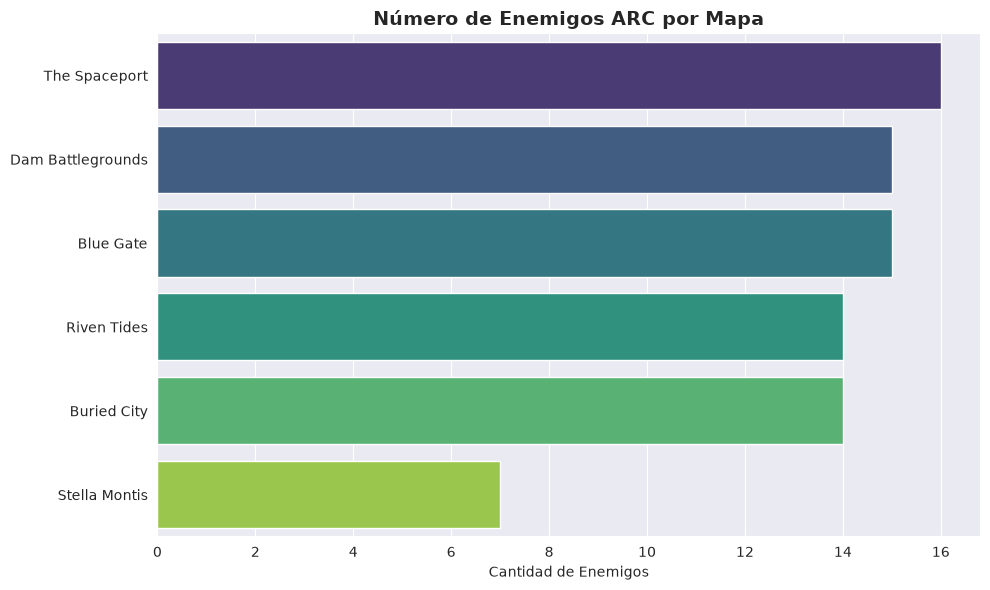

In [3]:
enemies_per_map = pd.read_sql("""
SELECT m.name as mapa, COUNT(DISTINCT em.enemy_id) as num_enemigos
FROM maps m
JOIN enemy_maps em ON m.id = em.map_id
GROUP BY m.name
ORDER BY num_enemigos DESC
""", conn)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=enemies_per_map, x="num_enemigos", y="mapa", ax=ax, palette="viridis")
ax.set_title("Número de Enemigos ARC por Mapa", fontsize=14, fontweight="bold")
ax.set_xlabel("Cantidad de Enemigos")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 3. Top enemigos por valor total de loot

/tmp/ipykernel_34780/1040442819.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=loot_value.head(10), x="valor_total", y="name", ax=ax, palette="magma")


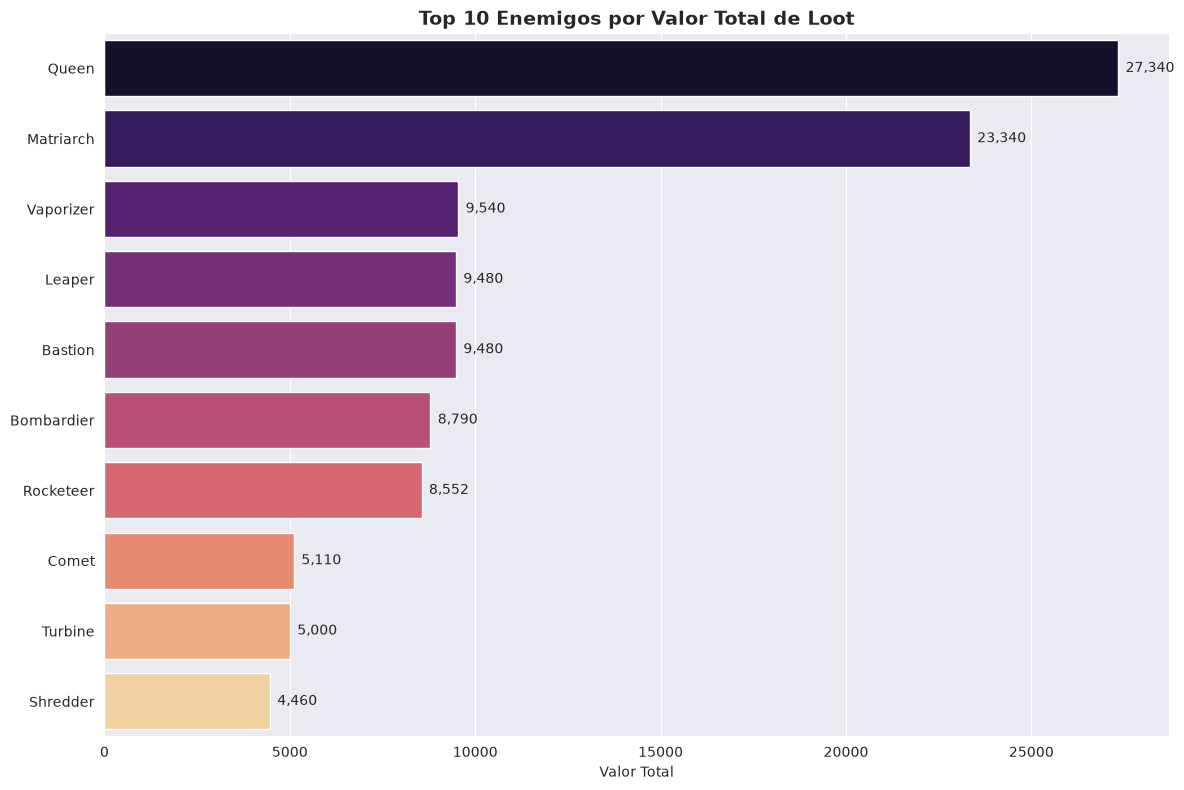

In [4]:
loot_value = pd.read_sql("""
SELECT e.name, 
       COUNT(ed.item_id) as items,
       ROUND(AVG(ed.value), 0) as valor_promedio,
       SUM(ed.value) as valor_total
FROM enemies e
JOIN enemy_drops ed ON e.id = ed.enemy_id
GROUP BY e.name
ORDER BY valor_total DESC
""", conn)

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(data=loot_value.head(10), x="valor_total", y="name", ax=ax, palette="magma")
ax.set_title("Top 10 Enemigos por Valor Total de Loot", fontsize=14, fontweight="bold")
ax.set_xlabel("Valor Total")
ax.set_ylabel("")

for i, v in enumerate(loot_value.head(10)["valor_total"]):
    ax.text(v + 200, i, f"{v:,.0f}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

## 4. Distribución de rareza por mapa

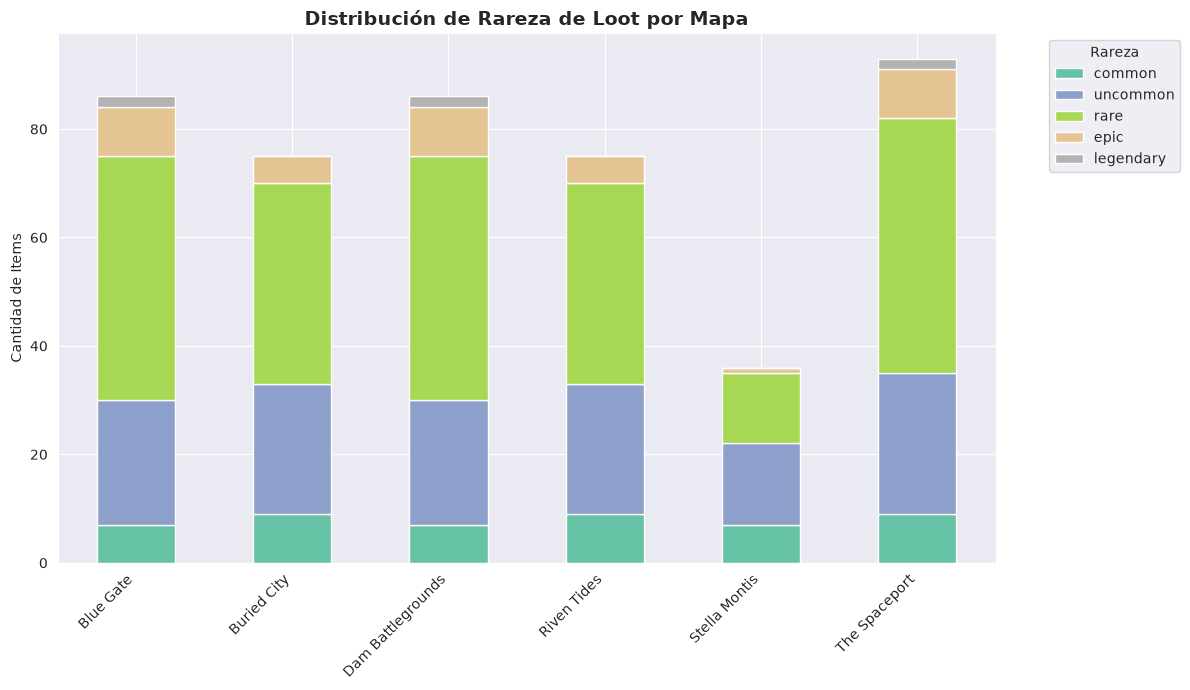

In [5]:
rarity_by_map = pd.read_sql("""
SELECT m.name as mapa, ed.rarity, COUNT(*) as cantidad
FROM maps m
JOIN enemy_maps em ON m.id = em.map_id
JOIN enemy_drops ed ON em.enemy_id = ed.enemy_id
GROUP BY m.name, ed.rarity
ORDER BY m.name, ed.rarity
""", conn)

rarity_pivot = rarity_by_map.pivot(index="mapa", columns="rarity", values="cantidad").fillna(0)
rarity_order = ["common", "uncommon", "rare", "epic", "legendary"]
rarity_pivot = rarity_pivot[[c for c in rarity_order if c in rarity_pivot.columns]]

fig, ax = plt.subplots(figsize=(12, 7))
rarity_pivot.plot(kind="bar", stacked=True, ax=ax, colormap="Set2")
ax.set_title("Distribución de Rareza de Loot por Mapa", fontsize=14, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Cantidad de Items")
ax.legend(title="Rareza", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5. Valor promedio vs cantidad de items por enemigo

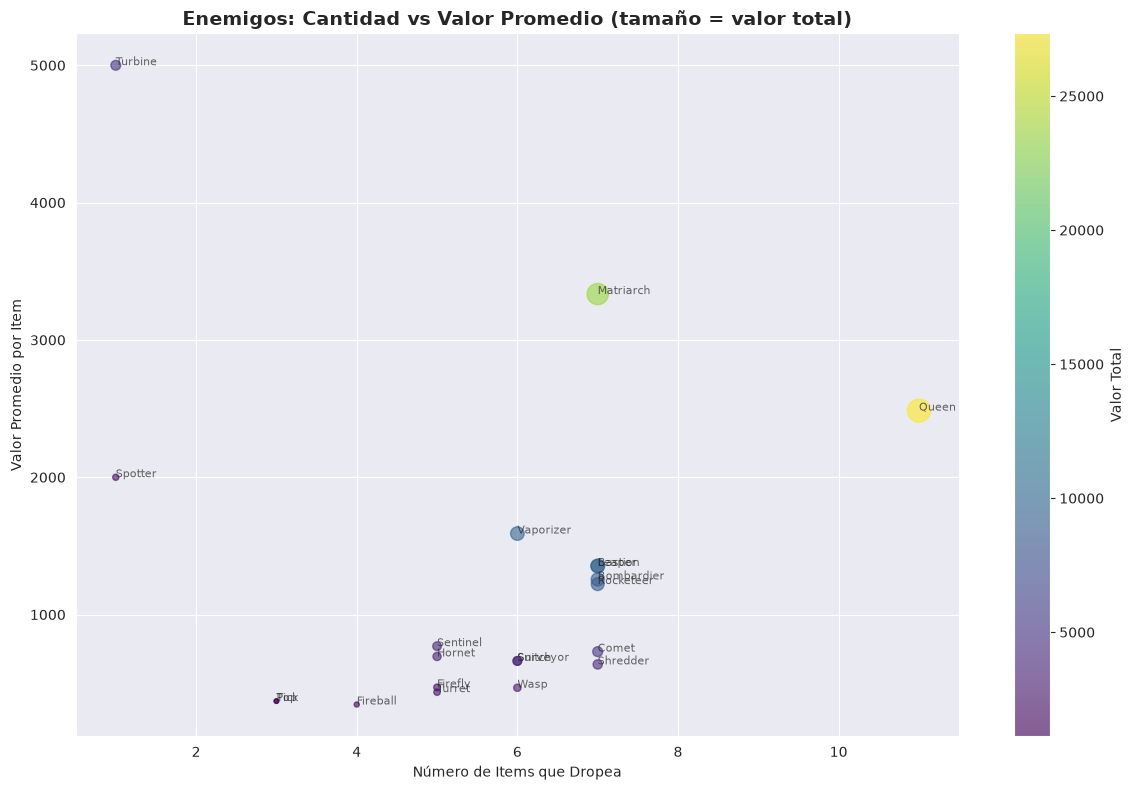

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(loot_value["items"], loot_value["valor_promedio"], 
                     s=loot_value["valor_total"]/100, 
                     alpha=0.6, c=loot_value["valor_total"], cmap="viridis")

for i, row in loot_value.iterrows():
    ax.annotate(row["name"], (row["items"], row["valor_promedio"]), 
                fontsize=8, alpha=0.7)

ax.set_title("Enemigos: Cantidad vs Valor Promedio (tamaño = valor total)", fontsize=14, fontweight="bold")
ax.set_xlabel("Número de Items que Dropea")
ax.set_ylabel("Valor Promedio por Item")
plt.colorbar(scatter, label="Valor Total")
plt.tight_layout()
plt.show()

## 6. Heatmap: Enemigos más valiosos por mapa

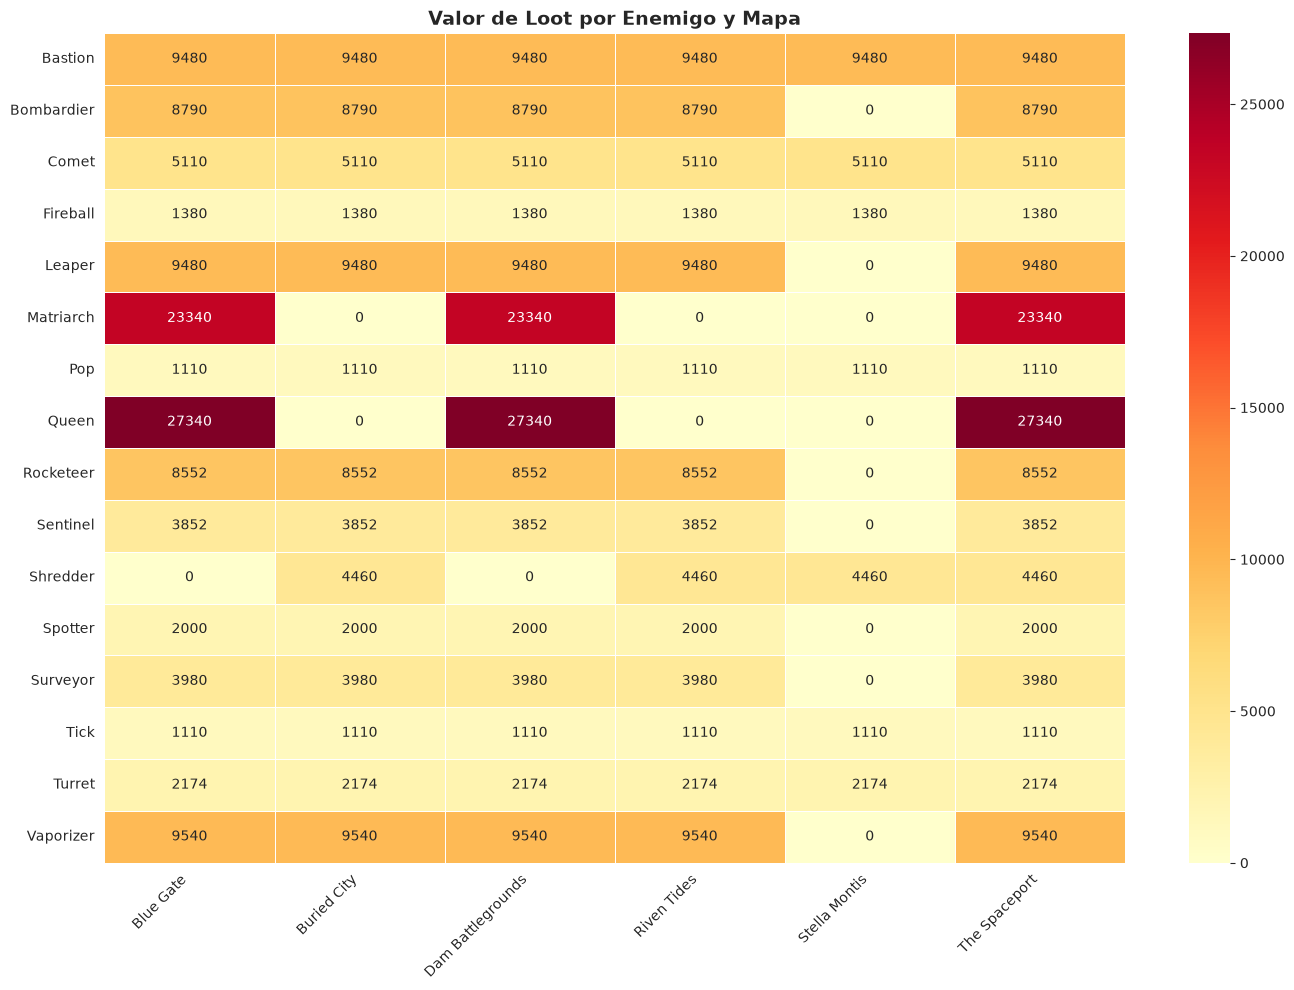

In [7]:
enemy_map_value = pd.read_sql("""
SELECT e.name as enemigo, m.name as mapa, SUM(ed.value) as valor_total
FROM enemies e
JOIN enemy_drops ed ON e.id = ed.enemy_id
JOIN enemy_maps em ON e.id = em.enemy_id
JOIN maps m ON em.map_id = m.id
GROUP BY e.name, m.name
""", conn)

heatmap_data = enemy_map_value.pivot(index="enemigo", columns="mapa", values="valor_total").fillna(0)

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax, linewidths=0.5)
ax.set_title("Valor de Loot por Enemigo y Mapa", fontsize=14, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Conclusiones

### Insights clave:

1. **Mejores enemigos para farmear:**
   - **Queen** es la mejor fuente de loot (27,340 valor total, 11 items)
   - **Matriarch** sigue con 23,340 valor total
   - Ambos tienen alto valor promedio por item

2. **Distribución por mapa:**
   - **The Spaceport** y **Dam Battlegrounds** tienen los items legendarios
   - **Blue Gate** y **Dam** tienen la mayor cantidad de items épicos
   - **Stella Montis** es el mapa más "pobre" en loot de alta rareza

3. **Recomendaciones de balance:**
   - Los jugadores nuevos deberían ir a **Blue Gate** o **Buried City** (balance entre dificultad y recompensa)
   - Para farmeo intensivo: buscar **Queen** y **Matriarch** (aparecen en múltiples mapas)
   - **Stella Montis** podría necesitar buffs en loot legendario/épico

4. **Desbalance detectado:**
   - Spaceport y Dam tienen 2 legendarios cada uno
   - Los otros mapas no tienen legendarios en drops de enemigos ARC

In [8]:
conn.close()